In [1]:
from config import TrainConfig
from data import load_tinystories

train_config = TrainConfig(num_train_stories=50, num_val_stories=10)

train_texts, val_texts = load_tinystories(
    train_config.num_train_stories, train_config.num_val_stories
)

print(f"Train stories: {len(train_texts)}")
print(f"Val stories:   {len(val_texts)}")
print(train_texts[0][:200])

Train stories: 50
Val stories:   10
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on


In [2]:
from config import TOKENIZER_VOCAB_SIZE
from tokenizer import build_encoding, train_tokenizer

tokenizer_state = train_tokenizer(train_texts + val_texts, vocab_size=TOKENIZER_VOCAB_SIZE)
encoding = build_encoding(tokenizer_state)

sample_text = train_texts[0][:200]
sample_ids = encoding.encode_ordinary(sample_text)

print(f"Vocab size: {encoding.n_vocab}")
print(f"Tokens for {len(sample_text)} chars: {len(sample_ids)}")
print(f"Round-trip matches original: {encoding.decode(sample_ids) == sample_text}")

Vocab size: 1988
Tokens for 200 chars: 46
Round-trip matches original: True


In [3]:
from data import make_dataloader

eot_token_id = tokenizer_state.eot_token_id

train_ids = [eot_token_id]
for document in train_texts:
    train_ids.extend(encoding.encode_ordinary(document) + [eot_token_id])

train_loader = make_dataloader(
    train_ids, batch_size=2, max_length=32, stride=32, shuffle=False, drop_last=True
)

input_batch, target_batch = next(iter(train_loader))
print("Input :", encoding.decode(input_batch[0].tolist()))
print("Target:", encoding.decode(target_batch[0].tolist()))

Input : <|EOT|>One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted
Target: One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to


In [4]:
from checkpoint import load_checkpoint
from sampling import generate_text
from train import get_device

device = get_device()

(
    model,
    gpt_config,
    ckpt_encoding,
    ckpt_eot_token_id,
    train_losses,
    val_losses,
    tokens_seen,
) = load_checkpoint("checkpoints/model.pt", device)

output_text = generate_text(
    model=model,
    encoding=ckpt_encoding,
    eot_token_id=ckpt_eot_token_id,
    prompt="Once upon a time,",
    max_tokens=200,
    ctx_len=gpt_config.ctx_len,
    device=device,
)
print(output_text)

<|EOT|>Once upon a time,cess new b� fish g got difficulrom sew learnednkedout couldn playedar wasittye nam sew learned some� climb topretendar was couir climbam play and diff happilyiousp and specialrabp rhinoceros healN the so happy ebw�am.xt sweeterosX til beep climbend� climb cher9.xt other\� and said hiamesitty�nedgether<|EOT|>


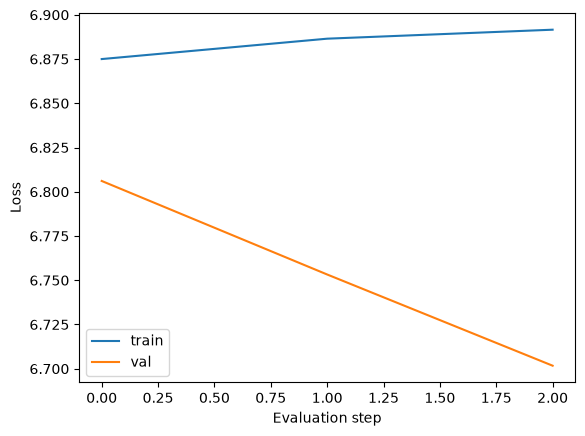

In [5]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.xlabel("Evaluation step")
plt.ylabel("Loss")
plt.legend()
plt.show()